# Difference-in-Differences, Event Studies, and Synthetic Control

**What you'll learn**

- The 2x2 DiD logic and why it beats both naive before/after and treated-vs-control cross-sections — demonstrated in a simulated policy rollout where all three are computed against a known truth.
- The regression formulation (`treated x post` interaction, two-way fixed effects), why you must cluster standard errors by unit, and how to build and read an **event-study plot** with leads and lags.
- What parallel-trends violations do to DiD, and how the event study's pre-period coefficients reveal them.
- Why naive two-way fixed effects (TWFE) can be badly wrong under **staggered adoption** with heterogeneous dynamic effects — including a sign flip — and which modern estimators fix it (Callaway–Sant'Anna, Sun–Abraham, stacked DiD).
- **Synthetic control** end-to-end for a one-city launch: donor pool, convex weights via constrained optimization (scipy), pre-period fit, gap plot, and inference by in-space placebo tests.
- A decision framework: given treated-unit count, data granularity, and trend plausibility, which tool do you reach for?

**Why it matters in interviews**

- "We launched in 3 cities — how do you measure the impact?" is one of the most common senior DS/AS case questions. This notebook *is* the answer.
- Interviewers probe whether you treat parallel trends as an assumption to defend (event study, placebos) or a phrase to recite. The former reads senior.
- Staggered-rollout TWFE pitfalls are a current-events litmus test: the econometrics changed around 2018–2021, and interviewers at causal-inference-heavy shops ask about it.
- "How do you do inference with one treated unit?" separates candidates who have actually run a geo launch analysis from those who haven't.

Prerequisites from this module: estimands and assumption language from
[01_potential_outcomes_dags.ipynb](01_potential_outcomes_dags.ipynb); selection-on-observables
methods (the main alternative identification strategy) in
[02_propensity_ipw_doubly_robust.ipynb](02_propensity_ipw_doubly_robust.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.optimize import minimize

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.dpi": 100,
})

## 1. The 2x2 DiD: a policy rollout with parallel trends

**Business setting.** A food-delivery marketplace cuts delivery fees in 20 of its 40
regions starting in month 12 of a 24-month window. Outcome: weekly orders per 10k
residents (an "orders index"). The rollout was *not* randomized — ops picked
already-strong regions — and the whole market is growing. By construction:

- Region fixed effects $\alpha_i$: treated regions start ~12 index points higher
  (selection on *levels*).
- Common time effects $\lambda_t$: an upward market trend (+0.5/month) plus seasonality —
  shared by all regions (this is the **parallel trends** world).
- Serially correlated region-level shocks (AR(1), $\rho = 0.6$) — realistic, and exactly
  what makes naive standard errors lie later.
- **True treatment effect $\tau = 5$** index points, constant after launch.

$$y_{it} = \alpha_i + \lambda_t + \tau \, D_{it} + \varepsilon_{it}, \qquad
D_{it} = \text{treated}_i \times \mathbf{1}[t \ge 12]$$

The identifying assumption is **parallel trends**: absent treatment, treated and control
group means would have moved in parallel — $E[y_{it}(0)]$ differences are constant over
time. Note what it does *not* require: levels can differ arbitrarily (selection on levels
is fine; selection on *trends* is fatal).

In [2]:
N_TREATED, N_CONTROL, N_MONTHS, T_STAR = 20, 20, 24, 12
TAU = 5.0


def make_panel(extra_trend_treated=0.0, tau=TAU, rho=0.6, sigma=1.0):
    """Region x month panel. extra_trend_treated adds a differential slope for
    treated regions (0 => parallel trends hold)."""
    n = N_TREATED + N_CONTROL
    treated = np.repeat([1, 0], [N_TREATED, N_CONTROL])
    alpha = np.where(treated == 1, rng.normal(52, 6, n), rng.normal(40, 6, n))
    months = np.arange(N_MONTHS)
    lam = 0.5 * months + 2.0 * np.sin(2 * np.pi * months / 12)   # common trend + seasonality
    eps = np.zeros((n, N_MONTHS))
    eps[:, 0] = rng.normal(0, sigma / np.sqrt(1 - rho**2), n)    # stationary start
    for t in range(1, N_MONTHS):
        eps[:, t] = rho * eps[:, t - 1] + rng.normal(0, sigma, n)
    D = treated[:, None] * (months[None, :] >= T_STAR)
    y = (alpha[:, None] + lam[None, :]
         + extra_trend_treated * treated[:, None] * months[None, :]
         + tau * D + eps)
    return pd.DataFrame({
        "region": np.repeat(np.arange(n), N_MONTHS),
        "month": np.tile(months, n),
        "treated": np.repeat(treated, N_MONTHS),
        "post": np.tile((months >= T_STAR).astype(int), n),
        "D": D.ravel(),
        "orders": y.ravel(),
    })


panel = make_panel()
panel["event_time"] = panel["month"] - T_STAR
print(f"panel: {panel['region'].nunique()} regions x {N_MONTHS} months = {len(panel)} rows")
print(panel.head(3).round(2).to_string(index=False))

panel: 40 regions x 24 months = 960 rows
 region  month  treated  post  D  orders  event_time
      0      0        1     0  0   54.40         -12
      0      1        1     0  0   54.65         -11
      0      2        1     0  0   55.19         -10


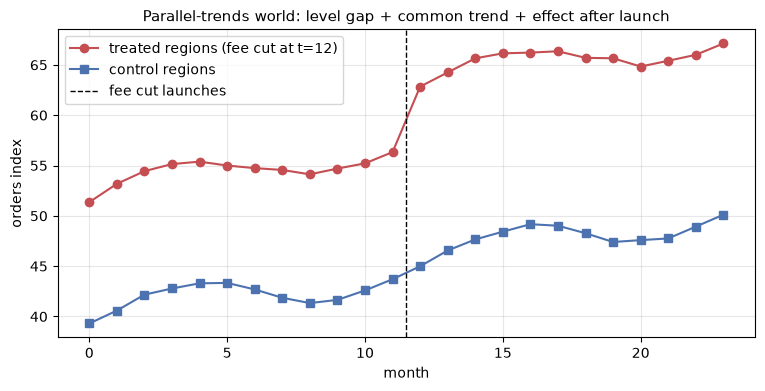

In [3]:
gm = panel.groupby(["treated", "month"])["orders"].mean().unstack(0)
fig, ax = plt.subplots()
ax.plot(gm.index, gm[1], "o-", color="#c44e52", label="treated regions (fee cut at t=12)")
ax.plot(gm.index, gm[0], "s-", color="#4c72b0", label="control regions")
ax.axvline(T_STAR - 0.5, color="k", ls="--", lw=1, label="fee cut launches")
ax.set_xlabel("month")
ax.set_ylabel("orders index")
ax.set_title("Parallel-trends world: level gap + common trend + effect after launch")
ax.legend()
plt.show()

### Three estimators, one truth

1. **Naive before/after** (treated regions only): $\bar y_{T,\text{post}} - \bar y_{T,\text{pre}}$.
   Confounded by anything else that changed over time — here the market trend
   (+0.5/month over a 12-month gap between period midpoints adds ~6).
2. **Naive cross-section** (post period only): $\bar y_{T,\text{post}} - \bar y_{C,\text{post}}$.
   Confounded by selection on levels — the ~12-point baseline gap.
3. **DiD** subtracts both nuisances: the control group's before/after change removes the
   common time trend; differencing within group removes fixed level gaps.

$$\hat\tau_{DiD} = (\bar y_{T,post} - \bar y_{T,pre}) - (\bar y_{C,post} - \bar y_{C,pre})$$

In [4]:
cell_means = panel.groupby(["treated", "post"])["orders"].mean().unstack("post")
cell_means.columns = ["pre", "post"]
cell_means.index = ["control", "treated"]
print("2x2 table of group means:")
print(cell_means.round(2).to_string(), "\n")

before_after = cell_means.loc["treated", "post"] - cell_means.loc["treated", "pre"]
cross_section = cell_means.loc["treated", "post"] - cell_means.loc["control", "post"]
did_22 = before_after - (cell_means.loc["control", "post"] - cell_means.loc["control", "pre"])

print(f"true effect tau                       = {TAU:6.2f}")
print(f"naive before/after (treated only)     = {before_after:6.2f}   <- eats the market trend")
print(f"naive cross-section (post only)       = {cross_section:6.2f}   <- eats the baseline gap")
print(f"difference-in-differences             = {did_22:6.2f}   <- recovers the truth")

2x2 table of group means:
           pre   post
control  42.11  47.99
treated  54.51  65.51 

true effect tau                       =   5.00
naive before/after (treated only)     =  11.00   <- eats the market trend
naive cross-section (post only)       =  17.52   <- eats the baseline gap
difference-in-differences             =   5.12   <- recovers the truth


The naive estimators are off by ~2x and ~3.5x in a world where DiD nails it. In an
interview, say the decomposition out loud: *before/after assumes no time effects;
cross-section assumes no selection; DiD replaces both with the single weaker assumption
of parallel trends.* Weaker — not weak. The rest of the notebook is about earning it.

## 2. Regression formulation, clustered SEs, and the event study

The 2x2 DiD is exactly the interaction coefficient in

$$y_{it} = \beta_0 + \beta_1\,\text{treated}_i + \beta_2\,\text{post}_t
           + \tau\,(\text{treated}_i \times \text{post}_t) + \varepsilon_{it}$$

and, more generally, the coefficient on $D_{it}$ in the **two-way fixed effects (TWFE)**
regression $y_{it} = \alpha_i + \lambda_t + \tau D_{it} + \varepsilon_{it}$. The regression
form is what you actually run: it gives standard errors, absorbs covariates, and extends
to event studies.

**Standard errors must be clustered by unit** (region). Outcomes within a region are
serially correlated over 24 months; iid-OLS treats 24 correlated observations as 24
independent ones and reports SEs that are far too small (Bertrand, Duflo & Mullainathan
2004 — we quantify the damage in the Pitfalls section). Cluster at the level at which
treatment is assigned — here the region. Same principle as cluster-randomized experiments
in [../02_ab_testing/05_ratio_metrics_delta_method.ipynb](../02_ab_testing/05_ratio_metrics_delta_method.ipynb).

In [5]:
m_inter = smf.ols("orders ~ treated * post", data=panel)
fit_inter_iid = m_inter.fit()
fit_inter_cl = m_inter.fit(cov_type="cluster", cov_kwds={"groups": panel["region"]})

m_twfe = smf.ols("orders ~ D + C(region) + C(month)", data=panel)
fit_twfe_iid = m_twfe.fit()
fit_twfe = m_twfe.fit(cov_type="cluster", cov_kwds={"groups": panel["region"]})

k = "treated:post"
print(f"interaction coefficient          = {fit_inter_cl.params[k]:.3f}"
      f"  (2x2 table gave {did_22:.3f})")
print(f"TWFE coefficient on D            = {fit_twfe.params['D']:.3f}")
print("\nfour SEs for the same effect:")
print(f"  pooled interaction, iid        = {fit_inter_iid.bse[k]:.3f}"
      f"   <- too BIG: between-region variance sits in the residual")
print(f"  TWFE, iid                      = {fit_twfe_iid.bse['D']:.3f}"
      f"   <- too SMALL: ignores within-region serial correlation")
print(f"  pooled interaction, clustered  = {fit_inter_cl.bse[k]:.3f}")
print(f"  TWFE, clustered                = {fit_twfe.bse['D']:.3f}"
      f"   <- clustering agrees across specs "
      f"({fit_twfe.bse['D'] / fit_twfe_iid.bse['D']:.1f}x the TWFE iid SE)")
ci = fit_twfe.conf_int().loc["D"]
print(f"\n95% CI (TWFE, clustered)         = [{ci[0]:.2f}, {ci[1]:.2f}]   truth = {TAU}")

interaction coefficient          = 5.118  (2x2 table gave 5.118)
TWFE coefficient on D            = 5.118

four SEs for the same effect:
  pooled interaction, iid        = 0.642   <- too BIG: between-region variance sits in the residual
  TWFE, iid                      = 0.152   <- too SMALL: ignores within-region serial correlation
  pooled interaction, clustered  = 0.282
  TWFE, clustered                = 0.291   <- clustering agrees across specs (1.9x the TWFE iid SE)

95% CI (TWFE, clustered)         = [4.55, 5.69]   truth = 5.0


The interaction regression reproduces the 2x2 number to machine precision, and TWFE agrees
(with one adoption date and a constant effect they estimate the same thing — remember that
caveat for Section 4). The SE comparison is the instructive part: iid SEs are wrong in
*both directions* depending on specification — inflated in the pooled form (region-level
heterogeneity pollutes the residual), understated in the FE form (serial correlation
ignored, here by ~2x) — while clustering by region gives essentially the same, correct
answer under either specification. That invariance is exactly what you want from your
inference.

### The event study: leads and lags

Replace the single $D_{it}$ with a full set of event-time dummies
$\sum_{k \ne -1} \gamma_k \, \mathbf{1}[\text{treated}_i,\ t - t^* = k]$, normalizing
$\gamma_{-1} = 0$ (the last pre-period is the reference). Two jobs:

- **Lags ($k \ge 0$)** trace the dynamic effect — does it jump, ramp, or fade?
- **Leads ($k < -1$)** are the falsification: treatment can't cause the past, so
  nonzero leads mean differential trends, anticipation, or composition change.
  Flat-leads-then-jump is the picture you want to show in every DiD you ever present.

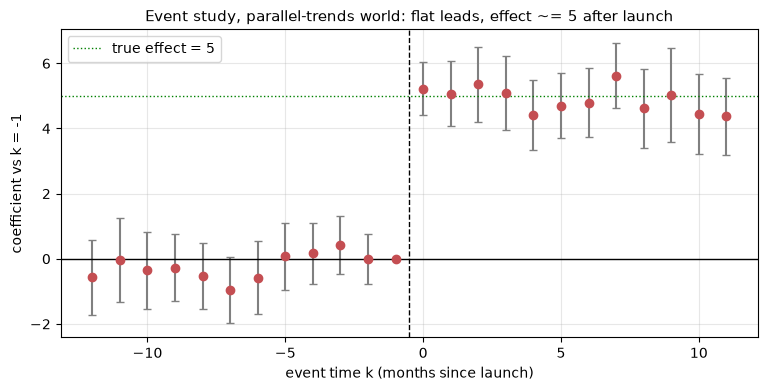

mean lead coefficient (k < -1) =  -0.24   (want ~= 0)
mean lag coefficient  (k >= 0) =   4.89   (truth = 5.0)


In [6]:
def event_study(df, y="orders", k_min=-12, k_max=11, omit=-1):
    """Event-study regression with unit & time FE, clustered by region.
    Returns (tidy coefficient frame, fitted model)."""
    df = df.copy()
    ks = [k for k in range(k_min, k_max + 1) if k != omit]
    names = []
    for k in ks:
        name = f"ev_m{-k}" if k < 0 else f"ev_p{k}"
        df[name] = ((df["treated"] == 1) & (df["event_time"] == k)).astype(int)
        names.append(name)
    formula = f"{y} ~ " + " + ".join(names) + " + C(region) + C(month)"
    fit = smf.ols(formula, data=df).fit(cov_type="cluster",
                                        cov_kwds={"groups": df["region"]})
    ci = fit.conf_int()
    out = pd.DataFrame({"k": ks,
                        "coef": fit.params[names].to_numpy(),
                        "lo": ci.loc[names, 0].to_numpy(),
                        "hi": ci.loc[names, 1].to_numpy()})
    ref = pd.DataFrame({"k": [omit], "coef": [0.0], "lo": [np.nan], "hi": [np.nan]})
    return (pd.concat([out, ref]).sort_values("k").reset_index(drop=True), fit)


def plot_event_study(es, ax, title):
    ax.errorbar(es["k"], es["coef"],
                yerr=[es["coef"] - es["lo"], es["hi"] - es["coef"]],
                fmt="o", capsize=3, color="#c44e52", ecolor="gray")
    ax.axhline(0, color="k", lw=1)
    ax.axhline(TAU, color="green", lw=1, ls=":", label=f"true effect = {TAU:.0f}")
    ax.axvline(-0.5, color="k", ls="--", lw=1)
    ax.set_xlabel("event time k (months since launch)")
    ax.set_ylabel("coefficient vs k = -1")
    ax.set_title(title)
    ax.legend()


es_clean, _ = event_study(panel)
fig, ax = plt.subplots()
plot_event_study(es_clean, ax, "Event study, parallel-trends world: flat leads, effect ~= 5 after launch")
plt.show()

mean_lead = es_clean.loc[es_clean["k"] < -1, "coef"].mean()
mean_lag = es_clean.loc[es_clean["k"] >= 0, "coef"].mean()
print(f"mean lead coefficient (k < -1) = {mean_lead:6.2f}   (want ~= 0)")
print(f"mean lag coefficient  (k >= 0) = {mean_lag:6.2f}   (truth = {TAU})")

Two senior-level caveats on pre-trend checks:

1. Flat leads are **necessary, not sufficient** — parallel trends is about the
   *counterfactual* post-period, which no pre-period test observes. A shock that hits
   only treated regions at t=12 (e.g., a competitor exits exactly where you launched)
   violates identification with perfectly flat leads.
2. "No significant lead" can just mean **low power**. Wide lead CIs are consistent with
   trends big enough to swamp your effect. Best current practice reports sensitivity
   analysis (Rambachan & Roth 2023: "what if post-period violations are as large as the
   worst pre-period one?") rather than stamping "pre-trends pass".

## 3. When parallel trends fail: DiD breaks, the event study tells you

Now the realistic ugly case: ops launched the fee cut in regions that were *already
growing faster* (chasing momentum — exactly how real rollouts get targeted). Same DGP
plus a differential slope of **+0.35/month** for treated regions. True effect is still 5.
DiD attributes the extra pre-existing growth to the treatment: the bias is
$0.35 \times (\bar t_{post} - \bar t_{pre}) = 0.35 \times 12 = +4.2$.

In [7]:
panel_bad = make_panel(extra_trend_treated=0.35)
panel_bad["event_time"] = panel_bad["month"] - T_STAR

fit_bad = smf.ols("orders ~ treated * post", data=panel_bad).fit(
    cov_type="cluster", cov_kwds={"groups": panel_bad["region"]})
print(f"true effect                    = {TAU:.2f}")
print(f"DiD estimate (violated PT)     = {fit_bad.params[k]:.2f}")
print(f"bias                           = {fit_bad.params[k] - TAU:+.2f}   (theory: +4.20)")

true effect                    = 5.00
DiD estimate (violated PT)     = 9.13
bias                           = +4.13   (theory: +4.20)


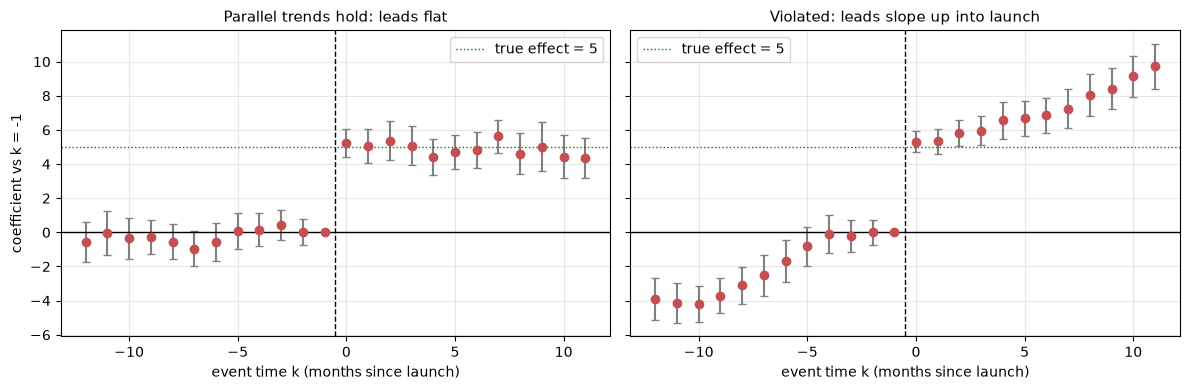

slope of lead coefficients in violated world = 0.469/month (true differential trend = 0.350)


In [8]:
es_bad, _ = event_study(panel_bad)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
plot_event_study(es_clean, axes[0], "Parallel trends hold: leads flat")
plot_event_study(es_bad, axes[1], "Violated: leads slope up into launch")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

lead_slope = np.polyfit(es_bad.loc[es_bad["k"] < 0, "k"],
                        es_bad.loc[es_bad["k"] < 0, "coef"], 1)[0]
print(f"slope of lead coefficients in violated world = {lead_slope:.3f}/month "
      f"(true differential trend = 0.350)")

The right-hand panel is the classic smoking gun: lead coefficients climb steadily into
the launch, and the "effect" after launch continues that line. The fitted lead slope
(0.47/month) is a noisy but unmistakable read on the differential trend we injected
(0.35/month). A DiD number reported without this plot is not evidence.

**What can you do when the pre-trend check fails?**

- **Conditional parallel trends**: if faster-growing regions are identifiable from
  covariates, adjust — regression with covariate-by-time interactions, or doubly robust
  DiD (propensity + outcome model, see
  [02_propensity_ipw_doubly_robust.ipynb](02_propensity_ipw_doubly_robust.ipynb)).
- **Change the control group**: synthetic control (Section 5) *builds* a control with
  matching pre-trends instead of assuming one.
- **Triple difference (DDD)**: add a within-region comparison group unaffected by the
  policy (e.g., a product line the fee cut doesn't touch) to difference out region trends.
- **Bound instead of point-estimate** (Rambachan–Roth honest DiD).
- Linear detrending is a last resort — it bakes in a strong functional-form assumption
  and extrapolates it post-treatment.

## 4. Staggered adoption: naive TWFE can flip the sign

Real rollouts rarely have one launch date. With **staggered adoption**, the natural move
is the same TWFE regression ($y_{it} = \alpha_i + \lambda_t + \tau D_{it}$). The
2018–2021 econometrics literature (Goodman-Bacon; de Chaisemartin & D'Haultfœuille;
Callaway & Sant'Anna; Sun & Abraham) showed this is a weighted average of all possible
2x2 comparisons — including **"forbidden" ones that use already-treated units as
controls**. If effects grow over time, the already-treated "control" is still trending
up from its own treatment; subtracting it pushes the estimate down, with some 2x2s
getting *negative* weight. Homogeneous constant effects: TWFE is fine. Heterogeneous
dynamic effects: it can be attenuated, zero, or sign-flipped.

**Simulation.** 30 regions in three cohorts of 10 adopt at t=4, 10, 16 over 20 periods
(no never-treated group — the worst case). Effects ramp with time since adoption, and
early adopters benefit most: slopes 1.5 / 1.0 / 0.5 index points per treated period.

In [9]:
cohort_slopes = {4: 1.5, 10: 1.0, 16: 0.5}
rows = []
unit = 0
for g, slope in cohort_slopes.items():
    for _ in range(10):
        a_i = rng.normal(50, 5)
        for t in range(20):
            ks = t - g
            tau_it = slope * (ks + 1) if ks >= 0 else 0.0
            rows.append((unit, t, g, int(ks >= 0), tau_it,
                         a_i + 0.3 * t + tau_it + rng.normal(0, 1.0)))
        unit += 1
stag = pd.DataFrame(rows, columns=["unit", "t", "cohort", "D", "tau_true", "y"])

true_att = stag.loc[stag["D"] == 1, "tau_true"].mean()
fit_stag = smf.ols("y ~ D + C(unit) + C(t)", data=stag).fit(
    cov_type="cluster", cov_kwds={"groups": stag["unit"]})
print(f"true ATT (avg effect over treated unit-periods) = {true_att:6.2f}")
print(f"naive TWFE estimate                             = {fit_stag.params['D']:6.2f}"
      f"  (SE {fit_stag.bse['D']:.2f})")

true ATT (avg effect over treated unit-periods) =   8.80
naive TWFE estimate                             =  -0.89  (SE 0.42)


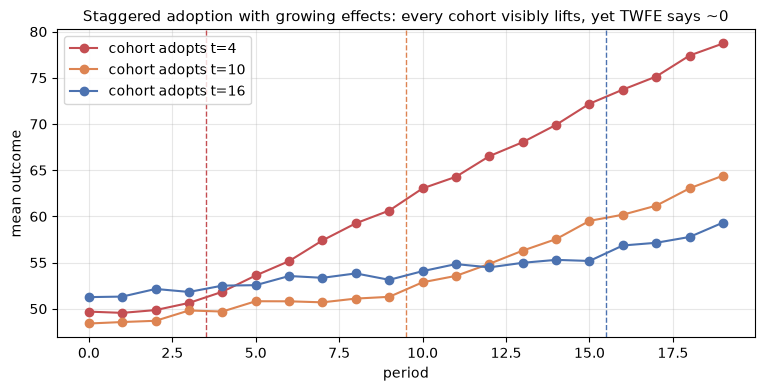

In [10]:
fig, ax = plt.subplots()
colors = {4: "#c44e52", 10: "#dd8452", 16: "#4c72b0"}
for g in cohort_slopes:
    cm = stag[stag["cohort"] == g].groupby("t")["y"].mean()
    ax.plot(cm.index, cm.values, "o-", color=colors[g], label=f"cohort adopts t={g}")
    ax.axvline(g - 0.5, color=colors[g], ls="--", lw=1)
ax.set_xlabel("period")
ax.set_ylabel("mean outcome")
ax.set_title("Staggered adoption with growing effects: every cohort visibly lifts, "
             "yet TWFE says ~0")
ax.legend()
plt.show()

Every cohort's outcome visibly jumps and keeps climbing after its own adoption — the
true average effect on the treated is large and positive — yet the TWFE coefficient is
roughly **zero-to-negative**. The late-vs-already-treated comparisons subtract the early
cohorts' still-growing effects and poison the average. This is not a small-sample fluke;
it is the estimator's algebra.

Sanity check: with a *homogeneous constant* effect, the same TWFE regression is fine.

In [11]:
stag_h = stag.copy()
stag_h["y"] = stag_h["y"] - stag_h["tau_true"] + 3.0 * stag_h["D"]   # constant tau = 3
fit_h = smf.ols("y ~ D + C(unit) + C(t)", data=stag_h).fit(
    cov_type="cluster", cov_kwds={"groups": stag_h["unit"]})
print(f"constant-effect world: truth = 3.00, TWFE = {fit_h.params['D']:.2f} "
      f"(SE {fit_h.bse['D']:.2f})  -> TWFE is fine here")

constant-effect world: truth = 3.00, TWFE = 2.84 (SE 0.14)  -> TWFE is fine here


**Modern fixes** (know the names and the one-line idea; implementation lives in
`did` / `csdid` / `pyfixest`):

- **Callaway & Sant'Anna (2021)**: estimate a clean 2x2 for each (cohort $g$, time $t$)
  cell using only never-treated or *not-yet-treated* units as controls, giving
  $ATT(g,t)$; aggregate with explicit, interpretable weights (by cohort, by event time).
  Exercise 2 builds a minimal version by hand.
- **Sun & Abraham (2021)**: interaction-weighted event study — saturate cohort x
  event-time dummies, then average; fixes contaminated event-study leads/lags under
  staggering.
- **Stacked DiD** (Cengiz et al. 2019): build a separate clean dataset per adoption
  event (treated cohort + not-yet-treated controls in a window), stack them with
  event-specific fixed effects. Conceptually simple, popular in industry.
- **Imputation estimators** (Borusyak, Jaravel & Spiess 2024): fit the FE model on
  untreated cells only, impute $y(0)$ for treated cells, average the gaps.

The interview take: *"TWFE with staggered timing is a weighted average of 2x2s, some
with negative weights when effects are dynamic; I'd use Callaway–Sant'Anna or a stacked
design, and always plot cohort-level event studies first."*

## 5. Synthetic control: a one-city launch

DiD needs a control *group* whose average tracks the treated average. When there is
**one treated unit** (a city launch, a state law, one country's reform), group averages
are gone and any single comparison city is arbitrary. **Synthetic control** (Abadie et
al.) builds the comparison: a convex combination of donor-pool cities chosen so the
weighted average *reproduces the treated city's pre-period trajectory*. Convexity
(weights $\ge 0$, summing to 1) prevents extrapolation outside the donor hull and makes
the counterfactual auditable — you can read off exactly which cities it is made of.

**Setting.** A marketplace launches a loyalty program in one city at week 40 of a
60-week window; 20 candidate donor cities never get it. Weekly GMV per capita follows a
2-factor model (cities load differently on a seasonal factor and a macro random walk),
so no single donor tracks the launch city — but a weighted blend can. **True effect:
+6 GMV index points** per post week.

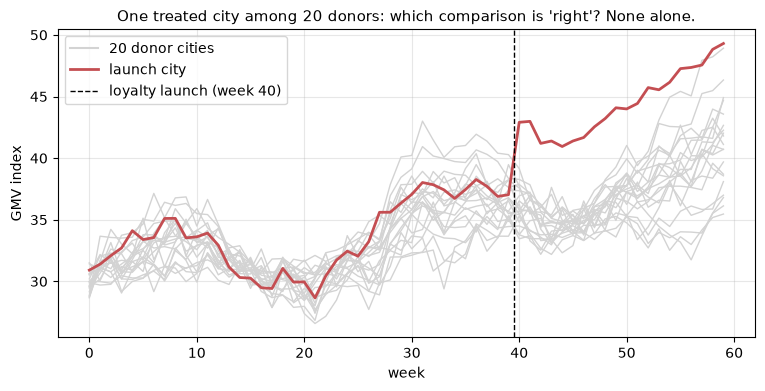

In [12]:
J, T0, T1 = 20, 40, 20               # donors, pre-weeks, post-weeks
T_TOT = T0 + T1
week = np.arange(T_TOT)

f_seasonal = 0.08 * week + 2.5 * np.sin(2 * np.pi * week / 26)   # factor 1
f_macro = np.cumsum(rng.normal(0, 0.5, T_TOT))                   # factor 2 (random walk)
load = rng.uniform(0, 2, (J, 2))                                 # donor factor loadings
w_true = np.zeros(J)
w_true[[2, 6, 11]] = [0.40, 0.35, 0.25]                          # treated = blend of 3 donors
load_treated = w_true @ load

delta_week = 30 + 0.10 * week
Y_don = (delta_week[:, None] + f_seasonal[:, None] * load[:, 0]
         + f_macro[:, None] * load[:, 1] + rng.normal(0, 0.8, (T_TOT, J)))
TRUE_SC_EFFECT = 6.0
y_launch = (delta_week + f_seasonal * load_treated[0] + f_macro * load_treated[1]
            + rng.normal(0, 0.8, T_TOT) + TRUE_SC_EFFECT * (week >= T0))

donor_names = [f"donor_{j:02d}" for j in range(J)]
fig, ax = plt.subplots()
ax.plot(week, Y_don, color="lightgray", lw=1)
ax.plot([], [], color="lightgray", label="20 donor cities")
ax.plot(week, y_launch, color="#c44e52", lw=2, label="launch city")
ax.axvline(T0 - 0.5, color="k", ls="--", lw=1, label="loyalty launch (week 40)")
ax.set_xlabel("week")
ax.set_ylabel("GMV index")
ax.set_title("One treated city among 20 donors: which comparison is 'right'? None alone.")
ax.legend()
plt.show()

### Weights by constrained least squares

Choose $w$ to minimize pre-period discrepancy
$\lVert y^{launch}_{pre} - Y^{donors}_{pre} w \rVert^2$ subject to $w_j \ge 0$,
$\sum_j w_j = 1$ — a convex QP we solve with SLSQP. (The full Abadie method matches on
a covariate vector with an outer optimization over predictor importance; matching on
all pre-period outcomes, as here, is the common simplification and works well with a
long pre-period.)

In [13]:
def fit_synth_weights(Y0_pre, y1_pre):
    """min ||y1 - Y0 w||^2  s.t.  w >= 0, sum(w) = 1."""
    Jn = Y0_pre.shape[1]

    def loss(w):
        r = y1_pre - Y0_pre @ w
        return r @ r

    def grad(w):
        return -2 * Y0_pre.T @ (y1_pre - Y0_pre @ w)

    res = minimize(loss, np.full(Jn, 1 / Jn), jac=grad, method="SLSQP",
                   bounds=[(0.0, 1.0)] * Jn,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1,
                                 "jac": lambda w: np.ones_like(w)}],
                   options={"maxiter": 1000, "ftol": 1e-12})
    w = np.clip(res.x, 0, None)
    return w / w.sum()


w_hat = fit_synth_weights(Y_don[:T0], y_launch[:T0])
wtab = (pd.Series(w_hat, index=donor_names, name="weight")
        .loc[lambda s: s > 0.01].sort_values(ascending=False))
print("donors with weight > 0.01:")
print(wtab.round(3).to_string())
print(f"\n(data built as 0.40*donor_02 + 0.35*donor_06 + 0.25*donor_11; "
      f"weights are not uniquely identified —\n several blends match the same factor "
      f"loadings, which is fine: the counterfactual is what matters)")

donors with weight > 0.01:
donor_13    0.197
donor_11    0.190
donor_17    0.185
donor_19    0.163
donor_02    0.140
donor_14    0.087
donor_10    0.039

(data built as 0.40*donor_02 + 0.35*donor_06 + 0.25*donor_11; weights are not uniquely identified —
 several blends match the same factor loadings, which is fine: the counterfactual is what matters)


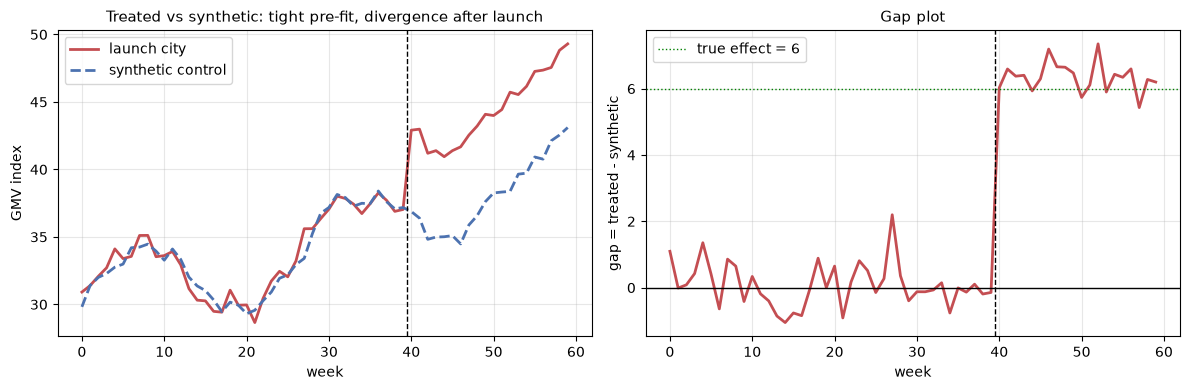

pre-period RMSPE          =  0.66   (fit quality — report this)
avg post-period gap       =  6.35   (truth = 6.0)
post/pre RMSPE ratio      =   9.6


In [14]:
y_synth = Y_don @ w_hat
gap = y_launch - y_synth
pre_rmspe = float(np.sqrt(np.mean(gap[:T0] ** 2)))
post_rmspe = float(np.sqrt(np.mean(gap[T0:] ** 2)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(week, y_launch, color="#c44e52", lw=2, label="launch city")
axes[0].plot(week, y_synth, color="#4c72b0", lw=2, ls="--", label="synthetic control")
axes[0].axvline(T0 - 0.5, color="k", ls="--", lw=1)
axes[0].set_xlabel("week")
axes[0].set_ylabel("GMV index")
axes[0].set_title("Treated vs synthetic: tight pre-fit, divergence after launch")
axes[0].legend()
axes[1].plot(week, gap, color="#c44e52", lw=2)
axes[1].axhline(0, color="k", lw=1)
axes[1].axhline(TRUE_SC_EFFECT, color="green", ls=":", lw=1,
                label=f"true effect = {TRUE_SC_EFFECT:.0f}")
axes[1].axvline(T0 - 0.5, color="k", ls="--", lw=1)
axes[1].set_xlabel("week")
axes[1].set_ylabel("gap = treated - synthetic")
axes[1].set_title("Gap plot")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"pre-period RMSPE          = {pre_rmspe:5.2f}   (fit quality — report this)")
print(f"avg post-period gap       = {gap[T0:].mean():5.2f}   (truth = {TRUE_SC_EFFECT:.1f})")
print(f"post/pre RMSPE ratio      = {post_rmspe / pre_rmspe:5.1f}")

### Inference with one treated unit: in-space placebos

No clustering, no CLT — with $N_{treated}=1$ classical standard errors are meaningless.
Abadie's answer is **permutation-style placebo tests**: run the identical procedure
pretending each donor city was treated at week 40 (donor pool = the other 19). If the
launch city's post-launch divergence is within the spread of placebo divergences, we've
learned nothing. The test statistic that controls for fit quality is the
**post/pre RMSPE ratio** — a big post gap only counts if the pre-fit was tight. The
permutation p-value is the treated unit's rank:
$p = \text{rank}/(J+1)$, so with 20 donors the *best possible* p-value is
$1/21 \approx 0.048$ — know that granularity limit.

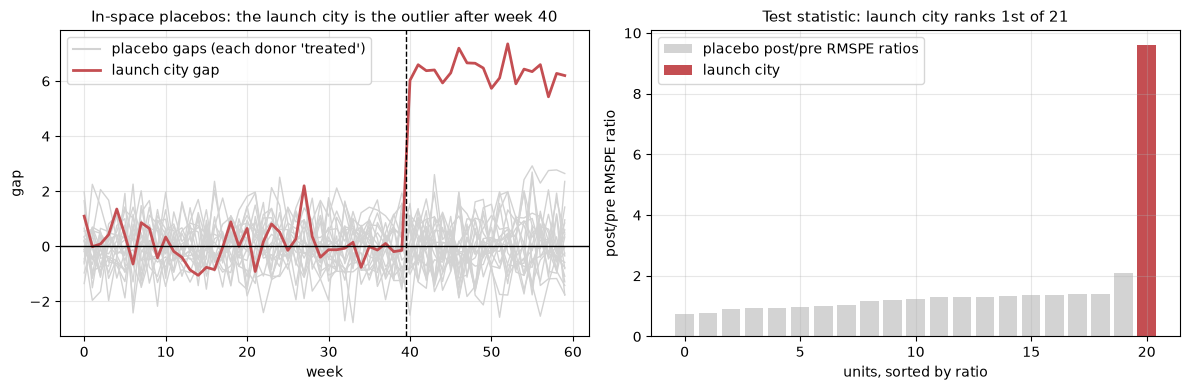

launch-city ratio = 9.6; largest placebo ratio = 2.09
permutation p-value = 1/21 = 0.048


In [15]:
placebo_gaps = np.zeros((T_TOT, J))
for j in range(J):
    others = np.delete(np.arange(J), j)
    w_j = fit_synth_weights(Y_don[:T0][:, others], Y_don[:T0, j])
    placebo_gaps[:, j] = Y_don[:, j] - Y_don[:, others] @ w_j

pl_pre = np.sqrt(np.mean(placebo_gaps[:T0] ** 2, axis=0))
pl_post = np.sqrt(np.mean(placebo_gaps[T0:] ** 2, axis=0))
pl_ratio = pl_post / pl_pre
treated_ratio = post_rmspe / pre_rmspe
rank = int(1 + (pl_ratio >= treated_ratio).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(week, placebo_gaps, color="lightgray", lw=1)
axes[0].plot([], [], color="lightgray", label="placebo gaps (each donor 'treated')")
axes[0].plot(week, gap, color="#c44e52", lw=2, label="launch city gap")
axes[0].axvline(T0 - 0.5, color="k", ls="--", lw=1)
axes[0].axhline(0, color="k", lw=1)
axes[0].set_xlabel("week")
axes[0].set_ylabel("gap")
axes[0].set_title("In-space placebos: the launch city is the outlier after week 40")
axes[0].legend()
axes[1].bar(range(J), np.sort(pl_ratio), color="lightgray",
            label="placebo post/pre RMSPE ratios")
axes[1].bar([J], [treated_ratio], color="#c44e52", label="launch city")
axes[1].set_xlabel("units, sorted by ratio")
axes[1].set_ylabel("post/pre RMSPE ratio")
axes[1].set_title("Test statistic: launch city ranks 1st of 21")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"launch-city ratio = {treated_ratio:.1f}; largest placebo ratio = {pl_ratio.max():.2f}")
print(f"permutation p-value = {rank}/{J + 1} = {rank / (J + 1):.3f}")

Practical notes a senior candidate should volunteer:

- **Screen placebos on pre-fit**: a donor whose synthetic control fits terribly pre-period
  produces a garbage ratio; Abadie drops placebos with pre-RMSPE, say, >5x the treated
  unit's (all our placebos fit well, so nothing is dropped here).
- **Donor-pool hygiene**: exclude cities plausibly hit by spillovers (neighboring metros,
  shared marketing budgets) and by their own contemporaneous shocks or interventions.
- Report the **weight table** and run **leave-one-out** on high-weight donors
  (Exercise 3) — one idiosyncratic donor shouldn't carry the result.
- Alternatives to know by name: **synthetic DiD** (Arkhangelsky et al. 2021 — unit *and*
  time weights, relaxes perfect pre-fit), augmented/ridge SC (allows mild extrapolation
  with a bias correction), and conformal inference for SC (Chernozhukov et al.).

## 6. Decision guidance: which tool, when

"Experiment impossible" is where the money questions live. The choice is driven by
**how many treated units**, **what data granularity**, and **how defensible parallel
trends is**:

| Situation | Reach for | Why / inference |
|---|---|---|
| Randomization feasible (even at geo level) | A designed experiment — geo experiments, switchbacks ([../02_ab_testing/06_advanced_designs_interference.ipynb](../02_ab_testing/06_advanced_designs_interference.ipynb)) | Design beats adjustment; do this whenever you can |
| Many treated + many control units, common launch date, panel data | DiD via TWFE + event study | Cluster-robust SEs by unit; leads as the falsification |
| Staggered launch dates, effects may be dynamic | Callaway–Sant'Anna / Sun–Abraham / stacked DiD | Never naive TWFE with heterogeneous timing |
| Parallel trends doubtful, adoption predictable from covariates | Conditional DiD / doubly robust DiD ([02_propensity_ipw_doubly_robust.ipynb](02_propensity_ipw_doubly_robust.ipynb)) | PT assumed *within* covariate strata |
| 1 (or 2–3) treated units, aggregate series, long pre-period | Synthetic control (per treated unit) | Placebo/permutation inference; report pre-RMSPE + weights |
| Few treated, short pre-period, or hull violations | Synthetic DiD / augmented SC; be humble | Perfect pre-fit unattainable or overfit (see Pitfall 3) |
| Treatment assigned by a threshold rule | RDD; policy shifts as instruments -> IV ([04_iv_rdd.ipynb](04_iv_rdd.ipynb)) | Different identification currency entirely |

Sample-size reality check: DiD inference leans on many *clusters*, not many rows.
40 regions is comfortable; 6 regions is wild-bootstrap territory; 1 region is
placebo-inference territory. The number of treated units is the first question to ask —
it determines the method *and* the inference.

## 7. Pitfalls

### Pitfall 1: unclustered SEs with serially correlated outcomes

The Bertrand–Duflo–Mullainathan (2004) result, reproduced in 30 seconds: simulate a
**zero-effect** world with AR(1) region shocks ($\rho = 0.8$), assign a *placebo*
treatment to a random half of regions, and test $H_0: \tau = 0$ at the 5% level, 400
times. iid-OLS should reject ~5% of the time; watch what it actually does.

In [16]:
def placebo_did_rejections(n_reps=400, n_units=30, n_periods=20, rho=0.8):
    rej_iid, rej_cl = 0, 0
    post = (np.arange(n_periods) >= n_periods // 2).astype(float)
    for _ in range(n_reps):
        eps = np.zeros((n_units, n_periods))
        eps[:, 0] = rng.normal(0, 1 / np.sqrt(1 - rho**2), n_units)
        for t in range(1, n_periods):
            eps[:, t] = rho * eps[:, t - 1] + rng.normal(0, 1, n_units)
        treat = np.zeros(n_units)
        treat[rng.choice(n_units, n_units // 2, replace=False)] = 1
        y = (rng.normal(0, 1, n_units)[:, None] + eps).ravel()   # unit FE + AR(1) noise
        Tv = np.repeat(treat, n_periods)
        Pv = np.tile(post, n_units)
        X = sm.add_constant(np.column_stack([Tv, Pv, Tv * Pv]))
        fit = sm.OLS(y, X).fit()
        rej_iid += fit.pvalues[3] < 0.05
        fit_c = fit.get_robustcov_results(
            cov_type="cluster", groups=np.repeat(np.arange(n_units), n_periods))
        rej_cl += fit_c.pvalues[3] < 0.05
    return rej_iid / n_reps, rej_cl / n_reps


fpr_iid, fpr_cl = placebo_did_rejections()
print("false-positive rate at nominal 5%, zero true effect, AR(1) rho = 0.8:")
print(f"  iid OLS SEs        : {fpr_iid:.1%}   <- ~4x the nominal rate")
print(f"  clustered by region: {fpr_cl:.1%}   <- close to nominal")

false-positive rate at nominal 5%, zero true effect, AR(1) rho = 0.8:
  iid OLS SEs        : 20.8%   <- ~4x the nominal rate
  clustered by region: 3.8%   <- close to nominal


With persistent shocks, iid OLS finds a "significant policy effect" in roughly one of
every five pure-noise datasets — and it gets worse with more periods or stronger
persistence (BDM report ~45% with CPS-like data). Cluster at the unit level *always* in DiD; with fewer than ~30
clusters switch to the wild cluster bootstrap (`wildboottest` in Python, `boottest` in
Stata), and with 1–3 treated clusters use permutation/placebo inference as in Section 5.

### Pitfall 2: parallel trends is functional-form specific (levels vs logs)

Suppose treated regions are simply *bigger* (2x the GMV base) and the whole market grows
25% in the post period, with **zero treatment effect**. Trends are parallel in *logs*
(equal growth rates) but not in *levels* (the big group gains more absolute GMV). Your
choice of scale silently decides the estimand — and can manufacture an effect.

In [17]:
n_r, n_m = 20, 16          # 20 regions per arm, 8 pre + 8 post months
base = np.concatenate([rng.normal(40, 3, n_r), rng.normal(20, 3, n_r)])   # treated 2x
treated_ff = np.repeat([1, 0], n_r)
months_ff = np.arange(n_m)
growth = np.where(months_ff >= 8, 1.25, 1.0)                               # +25% for all
gmv = (base[:, None] * growth[None, :]
       * np.exp(rng.normal(0, 0.03, (2 * n_r, n_m))))                      # zero effect

ff = pd.DataFrame({
    "region": np.repeat(np.arange(2 * n_r), n_m),
    "treated": np.repeat(treated_ff, n_m),
    "post": np.tile((months_ff >= 8).astype(int), 2 * n_r),
    "gmv": gmv.ravel(),
})
ff["log_gmv"] = np.log(ff["gmv"])

for yv, label in [("gmv", "levels"), ("log_gmv", "logs  ")]:
    f = smf.ols(f"{yv} ~ treated * post", data=ff).fit(
        cov_type="cluster", cov_kwds={"groups": ff["region"]})
    ci_ff = f.conf_int().loc["treated:post"]
    print(f"DiD in {label}: {f.params['treated:post']:7.3f}   "
          f"95% CI [{ci_ff[0]:6.3f}, {ci_ff[1]:6.3f}]   (truth: no effect)")

DiD in levels:   4.748   95% CI [ 4.176,  5.320]   (truth: no effect)
DiD in logs  :   0.003   95% CI [-0.008,  0.014]   (truth: no effect)


Levels DiD reports a strongly "significant" ~+5 GMV effect that is pure arithmetic:
25% growth on a 2x base. Logs correctly finds ~0. Neither scale is universally right —
*think about the economics of how the counterfactual scales* (proportional shocks ->
logs; additive shocks -> levels) and show robustness on both. Kahn-Lang & Lang (2020)
make this point forcefully: if treated and control differ in levels, you owe an argument
for why the *chosen* scale is where trends are parallel.

### Pitfall 3: synthetic control with a short pre-period overfits

With 20 donors and only a handful of pre-period weeks, the convex fit has enough freedom
to match *noise*: the pre-fit looks great precisely because it is overfit, and the
post/pre RMSPE ratio — our test statistic — inflates for every unit even when nothing
happened. Same factor world as Section 5 but with **no treatment effect anywhere**: we
fit every unit as a pseudo-treated unit using (a) only the last 6 pre-weeks vs (b) all
40, and compare.

In [18]:
Y_null = np.column_stack([y_launch - TRUE_SC_EFFECT * (week >= T0), Y_don])  # remove effect
n_units_null = Y_null.shape[1]
res_rows = []
for T0_fit, tag in [(6, "short pre (6 wks)"), (40, "long pre (40 wks)")]:
    fit_win = np.arange(T0 - T0_fit, T0)          # last T0_fit pre-weeks
    for u in range(n_units_null):
        others = np.delete(np.arange(n_units_null), u)
        w_u = fit_synth_weights(Y_null[fit_win][:, others], Y_null[fit_win, u])
        g_u = Y_null[:, u] - Y_null[:, others] @ w_u
        res_rows.append({
            "setting": tag,
            "pre_rmspe": np.sqrt(np.mean(g_u[fit_win] ** 2)),
            "post_rmspe": np.sqrt(np.mean(g_u[T0:] ** 2)),
        })
overfit = pd.DataFrame(res_rows)
overfit["ratio"] = overfit["post_rmspe"] / overfit["pre_rmspe"]
summary = overfit.groupby("setting").agg(
    mean_pre_rmspe=("pre_rmspe", "mean"),
    mean_post_rmspe=("post_rmspe", "mean"),
    median_ratio=("ratio", "median"),
    p90_ratio=("ratio", lambda s: s.quantile(0.9)),
).round(2)
print("no true effect anywhere -> post/pre ratio should be ~1:")
print(summary.to_string())

worst = overfit.loc[overfit["setting"] == "short pre (6 wks)"].nlargest(1, "ratio").iloc[0]
print(f"\nmost extreme short-pre placebo: pre-RMSPE = {worst['pre_rmspe']:.1e} "
      f"-> ratio = {worst['ratio']:.1e}")
print("(a numerically perfect 6-week pre-fit divides the ratio by ~0 - pure overfit)")

no true effect anywhere -> post/pre ratio should be ~1:
                   mean_pre_rmspe  mean_post_rmspe  median_ratio  p90_ratio
setting                                                                    
long pre (40 wks)            0.82             0.94          1.19       1.38
short pre (6 wks)            0.46             1.03          2.11      10.62

most extreme short-pre placebo: pre-RMSPE = 4.1e-09 -> ratio = 2.8e+08
(a numerically perfect 6-week pre-fit divides the ratio by ~0 - pure overfit)


The short pre-period buys a (deceptively) tighter pre-fit while post-period errors are
unchanged — so the RMSPE *ratio* inflates across the board (median ~2.1 vs ~1.2 with no
effect anywhere), and in the extreme a near-perfect 6-week fit sends one placebo's ratio
to ~10^8. Lessons: (1) a beautiful pre-fit is **not** evidence the counterfactual is
right when donors >> pre-periods — you are interpolating noise; (2) this is exactly why
Abadie screens placebos on pre-fit quality before ranking ratios; (3) placebo inference
partially self-corrects (all placebo ratios inflate together) but the *point estimate*
is still unstable. Want a long pre-period — ideally several times the post-period — and
fewer, well-chosen donors over many arbitrary ones.

Two more pitfalls to name (no simulation needed):

- **Anticipation**: if regions ramp behavior before the official date (announced fee
  cuts, pre-launch marketing), the last "pre" periods are contaminated — the event study
  shows nonzero effects at k = -2, -1. Fix: shift the effective treatment date to the
  announcement, or drop the anticipation window from estimation.
- **Composition change**: DiD on repeated cross-sections (not panels) assumes the units
  sampled pre and post are comparable. A fee cut that attracts new, different customers
  into the treated regions changes *who* you average over — the "effect" mixes behavior
  change with mix shift.

## 8. Interview corner

**Q1. "We launched our product in 3 cities last quarter. Measure the impact."**
Structure first: no randomization, 3 treated units, aggregate city-week metrics. (1)
Define the metric and window; check for anticipation around the announcement. (2) Build
a donor pool of comparable non-launch cities; screen for spillovers (shared media
markets, adjacent metros). (3) Per-city synthetic control with pre-launch fit
diagnostics; also run DiD/event study across the 3 cities vs donors as a robustness
check. (4) Inference by in-space placebos per city; for a pooled read, permute the
3-city label across donors. (5) Report gaps with placebo bands, the weight tables, and
leave-one-out sensitivity. Close by proposing a *designed* geo experiment for the next
launch.

**Q2. "What if parallel trends is doubtful?"**
Diagnose: event-study leads, placebo-in-time DiD, compare trends on covariates. Then
escalate: condition on covariates (DR DiD) if adoption is predictable; switch to
synthetic control to construct trend-matched counterfactuals; triple-difference if an
unaffected within-region outcome exists; report Rambachan–Roth-style sensitivity bounds
instead of pretending the point estimate is exact. Never just say "the pre-trend test
was insignificant" — that can be a power statement, not a validation.

**Q3. "How do you do inference with a single treated unit?"**
Classical SEs are undefined — there's no sampling variation in one unit. Use permutation
logic: in-space placebos (refit on every donor, rank the post/pre RMSPE ratio, p =
rank/(J+1)), in-time placebos (fake earlier launch dates should show no effect), and
note the granularity floor (20 donors -> min p ~ 0.048). Mention conformal inference
(Chernozhukov et al.) as the modern formalization.

**Q4. "Why cluster standard errors in DiD, and at what level?"**
Outcomes are serially correlated within units, and treatment is assigned at the unit
level — residual correlation within clusters makes iid SEs far too small (BDM 2004;
our simulation: ~20% false positives at nominal 5%). Cluster at the assignment
level. Few clusters: wild cluster bootstrap. One or two treated clusters:
permutation/placebo inference instead.

**Q5. "Your staggered-rollout TWFE estimate looks tiny but every cohort's own event
study shows a lift. What's going on?"**
Forbidden comparisons: TWFE averages 2x2s that use already-treated units as controls;
with dynamic effects those comparisons subtract still-growing treatment effects and can
carry negative weights, attenuating or flipping the aggregate. Use Callaway–Sant'Anna
(not-yet-treated controls, explicit aggregation), Sun–Abraham, or stacked DiD.

**Q6. "DiD or synthetic control — how do you choose?"**
Count treated units and check pre-trends. Many treated units + plausible common trends:
DiD (cheap, transparent, classical inference). One/few treated units, aggregate series,
long pre-period, no single credible control: synthetic control. In between (few treated,
imperfect pre-fit): synthetic DiD. And if any form of randomization is on the table,
design an experiment instead of doing archaeology later.

**Q7. "Your event study shows a significant coefficient at k = -2. Ship the analysis?"**
No — first understand it. Anticipation (announcement effects) -> re-date treatment to
the announcement or exclude the window. Differential trend -> the identification is
broken; move to Q2's escalation path. One marginal lead among 11 could be noise (test
leads jointly), but a *pattern* of drifting leads is disqualifying. Presenting the plot
and the decision rule is the senior move; hiding the lead is the career-limiting one.

## 9. Key takeaways

- DiD = before/after minus the control group's before/after: it kills fixed level gaps
  and common time shocks, and needs only parallel *trends* — levels may differ freely.
- Run it as a regression (`treated x post` or TWFE) to get SEs and covariates; **always
  cluster by unit** — with serial correlation, iid SEs over-reject massively.
- The event study is the workhorse deliverable: flat leads are your credibility, lags
  are your dynamics. But flat leads are necessary, not sufficient — and can reflect low
  power.
- Parallel-trends violations show up as sloped leads; responses include conditional/DR
  DiD, synthetic control, DDD, or honest sensitivity bounds — not silent detrending.
- Naive TWFE under staggered adoption mixes in already-treated-as-control comparisons;
  with dynamic heterogeneous effects it can show ~0 while every cohort visibly lifts.
  Names to know: Goodman-Bacon, Callaway–Sant'Anna, Sun–Abraham, stacked DiD.
- Synthetic control = convex donor weights matching the pre-period; report the weight
  table, pre-RMSPE, gap plot. Convexity prevents extrapolation and keeps it auditable.
- With one treated unit, inference is by placebo permutation of the post/pre RMSPE
  ratio; p-value granularity is 1/(donors+1).
- Scale choice (levels vs logs) is part of the identifying assumption, not a styling
  decision; short pre-periods + many donors = overfit synthetic controls.
- Tool choice is driven by: number of treated units, data granularity, pre-period
  length, and how defensible (conditional) parallel trends is.

## 10. Exercises

**Exercise 1 — placebo-in-time.** Using only the pre-launch months (0–11) of the clean
`panel`, pretend the fee cut happened at month 6 and estimate the DiD with clustered
SEs. What should you see, and what does this test actually check?

**Exercise 2 — a minimal Callaway–Sant'Anna.** For the staggered world, estimate
$ATT(g, t)$ for each cohort/period cell as a 2x2 DiD using **not-yet-treated** units as
controls and period $g-1$ as the base period. Average over the estimable cells and
compare with the truth and with naive TWFE. Which cells are *not* estimable here, and
why?

**Exercise 3 — leave-one-out synthetic control.** Drop the highest-weight donor from
the pool, refit the weights, and recompute the average post-period gap. How fragile is
the estimate to any single donor?

In [19]:
# --- Solution 1 ---
pre_only = panel[panel["month"] < T_STAR].copy()
pre_only["fake_post"] = (pre_only["month"] >= 6).astype(int)
fit_placebo = smf.ols("orders ~ treated * fake_post", data=pre_only).fit(
    cov_type="cluster", cov_kwds={"groups": pre_only["region"]})
cip = fit_placebo.conf_int().loc["treated:fake_post"]
print(f"placebo-in-time DiD = {fit_placebo.params['treated:fake_post']:6.2f}, "
      f"95% CI [{cip[0]:.2f}, {cip[1]:.2f}]  -> consistent with 0, as it must be")
print("\nIt checks that treated/control were not already diverging pre-launch (a")
print("parallel-trends diagnostic on the pre-period). It cannot certify the")
print("counterfactual post-period — no pre-period test can.")

placebo-in-time DiD =   0.47, 95% CI [-0.16, 1.10]  -> consistent with 0, as it must be

It checks that treated/control were not already diverging pre-launch (a
parallel-trends diagnostic on the pre-period). It cannot certify the
counterfactual post-period — no pre-period test can.


In [20]:
# --- Solution 2 ---
cohorts = sorted(stag["cohort"].unique())
cells = []
for g in cohorts:
    treat_units = stag["cohort"] == g
    for t in range(g, 20):
        nyt = stag["cohort"] > t                      # not-yet-treated at time t
        if not nyt.any():
            continue                                  # no clean controls left
        y_t = stag[stag["t"] == t]
        y_b = stag[stag["t"] == g - 1]                # base period: last pre-period
        att_gt = ((y_t.loc[treat_units[stag["t"] == t].values, "y"].mean()
                   - y_b.loc[treat_units[stag["t"] == g - 1].values, "y"].mean())
                  - (y_t.loc[nyt[stag["t"] == t].values, "y"].mean()
                     - y_b.loc[nyt[stag["t"] == g - 1].values, "y"].mean()))
        true_gt = stag.loc[(stag["cohort"] == g) & (stag["t"] == t), "tau_true"].mean()
        cells.append({"g": g, "t": t, "att_hat": att_gt, "att_true": true_gt})
cs = pd.DataFrame(cells)
print(f"estimable (g,t) cells: {len(cs)} "
      f"(cohort 16 has none, and nothing after t=15 — once everyone is treated,\n"
      f" there are no clean controls; with universal adoption the estimand shrinks)")
print(f"\nmanual CS-style ATT (avg over estimable cells) = {cs['att_hat'].mean():6.2f}")
print(f"true ATT over the same cells                   = {cs['att_true'].mean():6.2f}")
print(f"naive TWFE (for contrast)                      = {fit_stag.params['D']:6.2f}")

estimable (g,t) cells: 18 (cohort 16 has none, and nothing after t=15 — once everyone is treated,
 there are no clean controls; with universal adoption the estimand shrinks)

manual CS-style ATT (avg over estimable cells) =   7.03
true ATT over the same cells                   =   7.67
naive TWFE (for contrast)                      =  -0.89


In [21]:
# --- Solution 3 ---
drop = wtab.index[0]
keep_idx = [j for j in range(J) if donor_names[j] != drop]
w_loo = fit_synth_weights(Y_don[:T0][:, keep_idx], y_launch[:T0])
gap_loo = y_launch - Y_don[:, keep_idx] @ w_loo
print(f"dropped highest-weight donor: {drop} (weight {wtab.iloc[0]:.3f})")
print(f"avg post gap, full pool      = {gap[T0:].mean():5.2f}")
print(f"avg post gap, leave-one-out  = {gap_loo[T0:].mean():5.2f}   (truth = {TRUE_SC_EFFECT:.1f})")
print("\nSmall movement = robust: other donors span the same factor space, so the")
print("counterfactual barely changes. Large movement would mean one donor carries the")
print("result — investigate that donor for idiosyncratic shocks before trusting it.")

dropped highest-weight donor: donor_13 (weight 0.197)
avg post gap, full pool      =  6.35
avg post gap, leave-one-out  =  6.22   (truth = 6.0)

Small movement = robust: other donors span the same factor space, so the
counterfactual barely changes. Large movement would mean one donor carries the
result — investigate that donor for idiosyncratic shocks before trusting it.
